In [1]:
# Install the packages this notebook needs.
# If they are already installed, this step is quick and harmless.
%pip install -q pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


# 01. How the index is built

## Start here, in plain words

Imagine you want one number that sums up how free people are in a
country. That is a hard job, because freedom has many sides. You
cannot measure it with one question.

The Human Freedom Index tries to do it in a careful, open way. It
takes many smaller measures, turns each one into a score from 0 to
10, and then averages them. A score of 10 means more freedom on
that measure, as the index defines it. A score of 0 means less.
The word average matters here. An average can hide big differences
inside a country, and this notebook shows that plainly.

## Who makes it, and what it is

The index is co-published by the Cato Institute and the Fraser
Institute. The 2025 edition, the newest edition named in the
sources for this project, uses 87 distinct indicators and covers
165 countries. The newest data year in that edition is 2023.

The dataset used for the numbers in this project is older. It is
the 2018 edition file, covering 2008 to 2016 for 162 countries.
That is a cut, and it is stated here on purpose. The 2025 file
could not be downloaded directly in this build, because the Cato
site returned a bot check error. So this project does not pretend
to show 2023 scores country by country. It shows 2008 to 2016
scores, and it uses the 2025 edition only for the headline facts
above, which are attributed to the Fraser Institute summary.

## The two halves

The overall score is the average of two halves, given equal weight.

1. Personal freedom. This covers civil liberties and personal
   choices, in seven areas: rule of law, security and safety,
   movement, religion, association and assembly and civil society,
   expression and information, and identity and relationships.
2. Economic freedom. This covers economic choices, in five areas:
   size of government, legal system and property rights, sound
   money, freedom to trade internationally, and regulation.

Equal weight is a choice made by the index makers. It is not a
law of nature. A reader who thinks personal freedom should count
more, or economic freedom should count more, would get a
different overall score. Keep that in mind for every chart that
follows.

## Limits, stated before any conclusion

First, an index is a summary, not a photograph. It depends on
which indicators were chosen, and on the data available for each
country and year. Second, scores can move when the method changes,
not only when life on the ground changes. Third, a country score
says nothing by itself about any one person in that country.
Fourth, this project reports scores as the index defines them.
It does not label countries as good or bad.

In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
ROOT = pathlib.Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
print('Data folder:', DATA)
print('Charts folder:', CHARTS)

Data folder: /home/hatch/workspace/repo-builds/human-freedom-index/data/processed
Charts folder: /home/hatch/workspace/repo-builds/human-freedom-index/charts


In [3]:
clean = pd.read_csv(DATA / 'freedom_clean.csv')
latest = pd.read_csv(DATA / 'freedom_latest.csv')
print('Rows in the clean file:', len(clean))
print('Years:', clean['year'].min(), 'to', clean['year'].max())
print('Countries:', clean['country'].nunique())
print('Latest year in the file:', latest['year'].iloc[0])
print(latest[['country', 'hf_score', 'pf_score', 'ef_score', 'hf_rank']].head(10).to_string(index=False))

Rows in the clean file: 1458
Years: 2008 to 2016
Countries: 162
Latest year in the file: 2016
       country  hf_score  pf_score  ef_score  hf_rank
   New Zealand  8.887410  9.284819      8.49      1.0
   Switzerland  8.787759  9.185518      8.39      2.0
     Hong Kong  8.776840  8.583680      8.97      3.0
     Australia  8.582219  9.184438      7.98      4.0
        Canada  8.565863  9.151727      7.98      5.0
   Netherlands  8.554421  9.398842      7.71      6.0
       Denmark  8.547820  9.325640      7.77      6.0
       Ireland  8.504565  8.939129      8.07      8.0
United Kingdom  8.497918  8.995836      8.00      8.0
       Finland  8.472184  9.294368      7.65     10.0


## Do the two halves move together?

If personal and economic freedom always moved together, one half
would be enough. The chart below tests that idea. Each dot is one
country in 2016. The horizontal axis is personal freedom. The
vertical axis is economic freedom. The diagonal line is where the
two scores are equal. Dots above the line score higher on
economic freedom than on personal freedom. Dots below it score
higher on personal freedom.

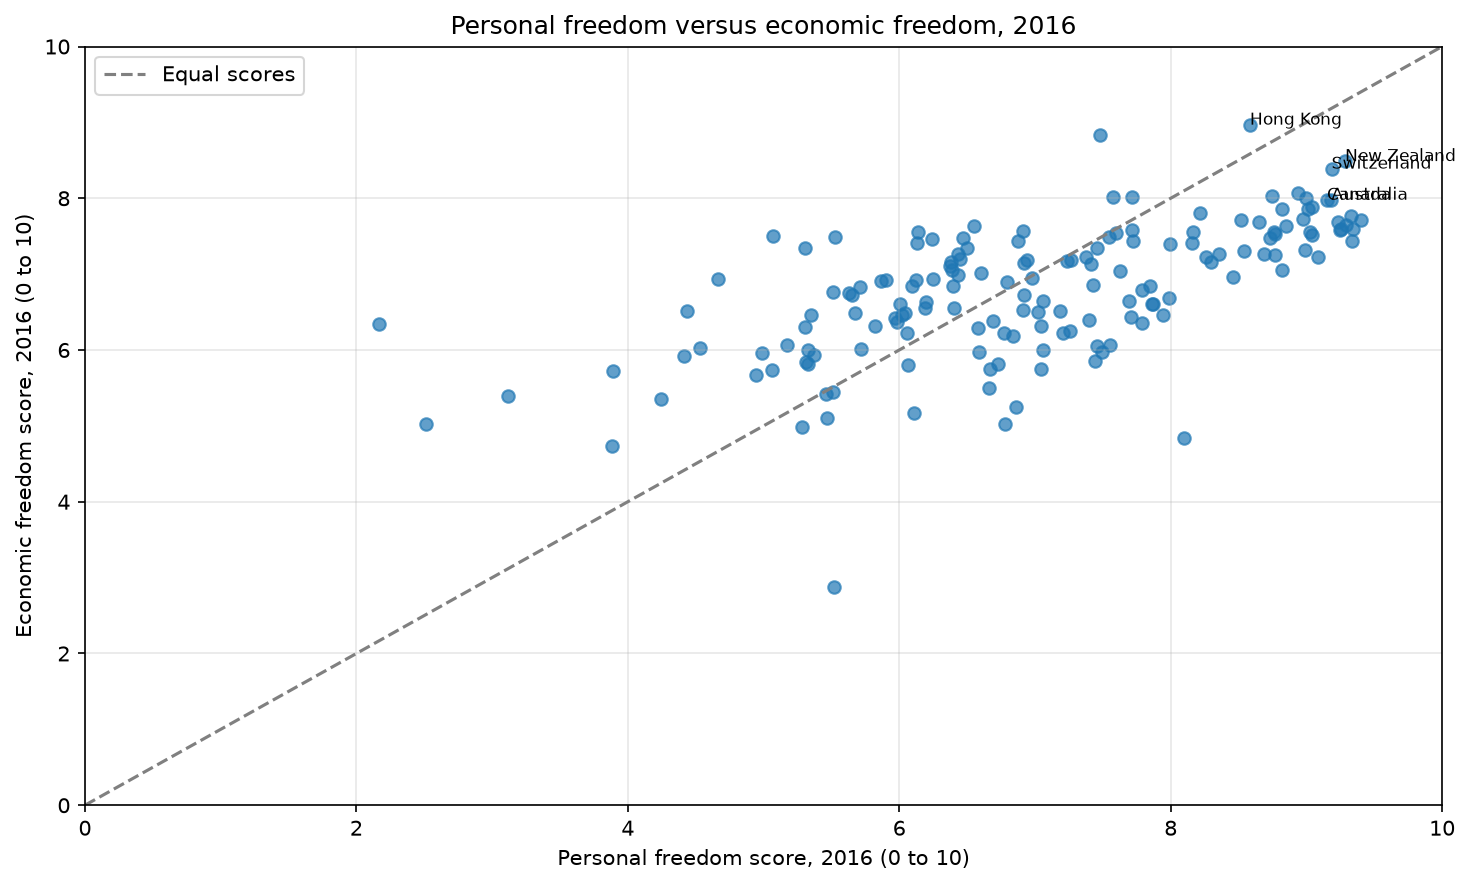

Correlation, personal versus economic, 2016: 0.627
Countries in 2016: 162


In [4]:
fig, ax = plt.subplots()
ax.scatter(latest['pf_score'], latest['ef_score'], alpha=0.7)
ax.plot([0, 10], [0, 10], color='grey', linestyle='--', label='Equal scores')
for _, row in latest.head(5).iterrows():
    ax.annotate(row['country'], (row['pf_score'], row['ef_score']), fontsize=8)
ax.set_xlabel('Personal freedom score, 2016 (0 to 10)')
ax.set_ylabel('Economic freedom score, 2016 (0 to 10)')
ax.set_title('Personal freedom versus economic freedom, 2016')
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_personal_vs_economic.png')
plt.show()
print('Correlation, personal versus economic, 2016:',
      round(latest['pf_score'].corr(latest['ef_score']), 3))
print('Countries in 2016:', len(latest))

## What sits inside personal freedom?

The next chart averages each personal freedom area across all
countries in 2016. It is a world average, not a score for any one
country. It shows which areas, on average, score higher or lower
in this dataset. That is useful, because it stops us from treating
personal freedom as one single thing.

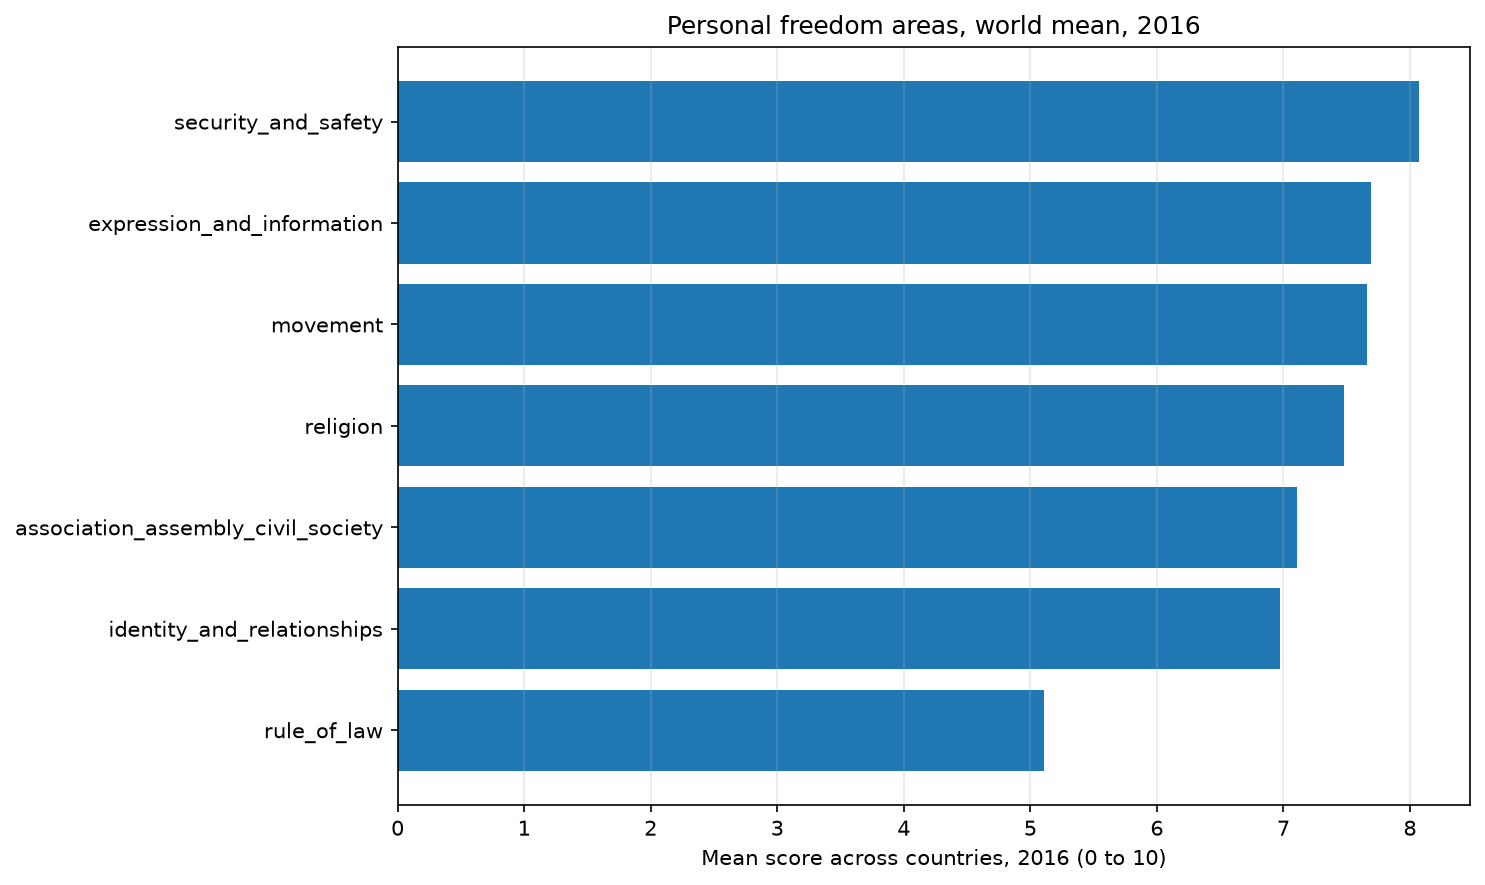

rule_of_law                           5.107
identity_and_relationships            6.976
association_assembly_civil_society    7.110
religion                              7.476
movement                              7.665
expression_and_information            7.689
security_and_safety                   8.071


In [5]:
personal_areas = ['rule_of_law', 'security_and_safety', 'movement',
                  'religion', 'association_assembly_civil_society',
                  'expression_and_information', 'identity_and_relationships']
means = latest[personal_areas].mean().sort_values()
fig, ax = plt.subplots()
ax.barh(means.index, means.values)
ax.set_xlabel('Mean score across countries, 2016 (0 to 10)')
ax.set_title('Personal freedom areas, world mean, 2016')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_personal_areas.png')
plt.show()
print(means.round(3).to_string())

## What sits inside economic freedom?

The same idea, for the five economic areas. Again, this is a
world mean for 2016. A high mean does not mean every country
scores high. It means the average is high.

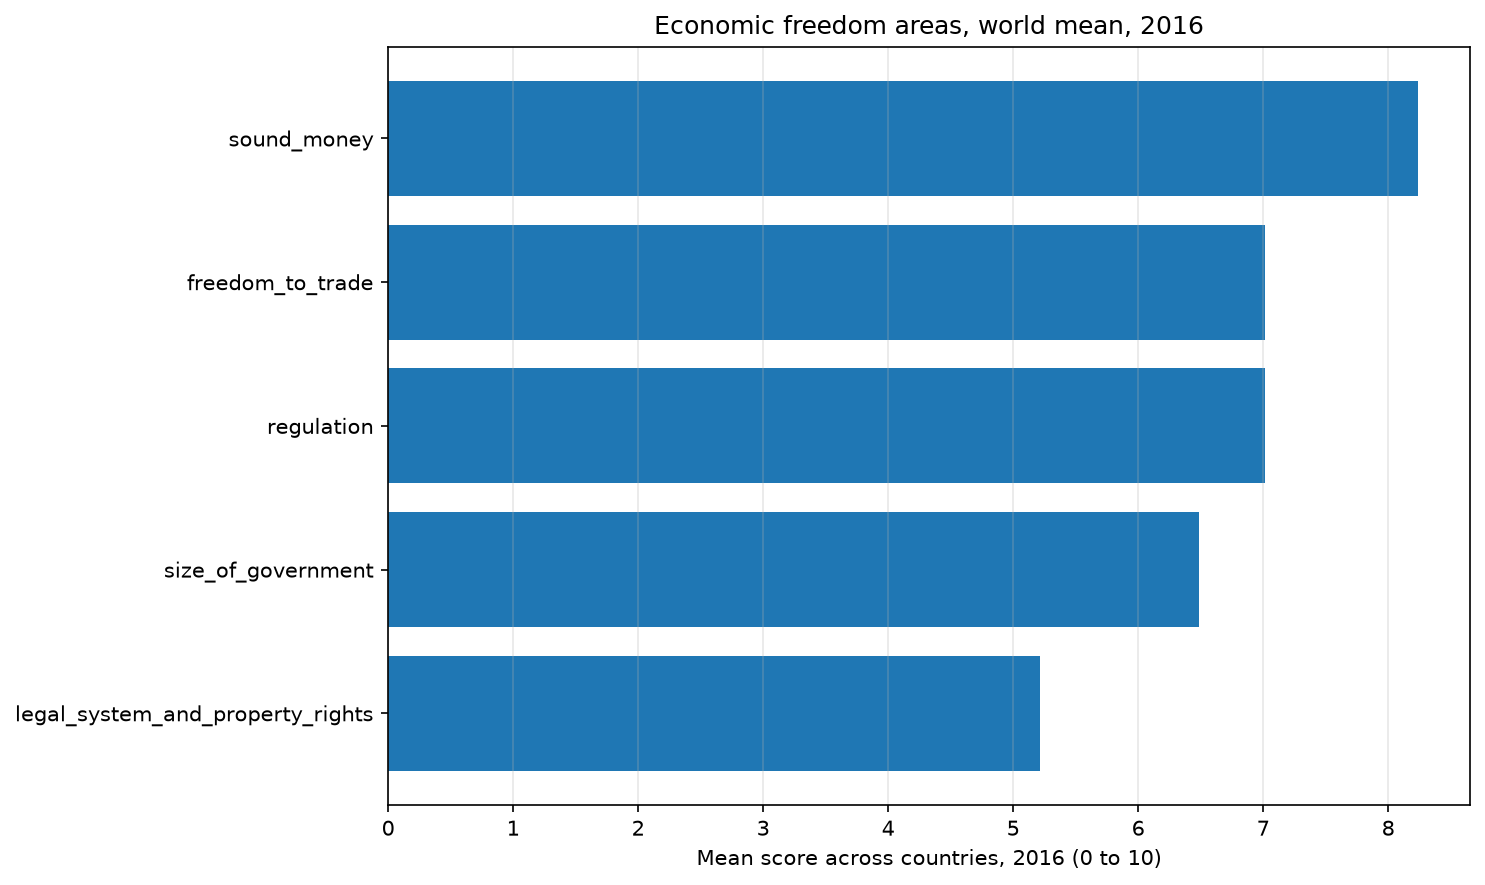

legal_system_and_property_rights    5.214
size_of_government                  6.484
regulation                          7.016
freedom_to_trade                    7.018
sound_money                         8.242


In [6]:
economic_areas = ['size_of_government', 'legal_system_and_property_rights',
                  'sound_money', 'freedom_to_trade', 'regulation']
means_e = latest[economic_areas].mean().sort_values()
fig, ax = plt.subplots()
ax.barh(means_e.index, means_e.values)
ax.set_xlabel('Mean score across countries, 2016 (0 to 10)')
ax.set_title('Economic freedom areas, world mean, 2016')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_economic_areas.png')
plt.show()
print(means_e.round(3).to_string())

## What to take away

The index is two averages joined into one average. The two halves
are related, but they are not the same, and the areas inside each
half differ. That is why later notebooks always show the overall
score together with its two halves, and why a single ranking is
never the whole story.